# Emmanuel Owusu Decision Tree Classification

Predict `is_carcinogenic` with a decision tree on the team's shared chemical-grouped split, tune it without letting chemicals leak between folds, and compare it directly against the Random Forest.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GroupKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

## 1. Load the shared split

In [2]:
X_train = pd.read_csv("../data/training/X_train.csv")
X_test = pd.read_csv("../data/training/X_test.csv")
y_train = pd.read_csv("../data/training/y_train.csv")["is_carcinogenic"]
y_test = pd.read_csv("../data/training/y_test.csv")["is_carcinogenic"]

print("train rows:", len(X_train), "| test rows:", len(X_test), "| features:", X_train.shape[1])
print("share carcinogenic in train:", round(y_train.mean(), 3), "| in test:", round(y_test.mean(), 3))

train rows: 5892 | test rows: 1353 | features: 364
share carcinogenic in train: 0.411 | in test: 0.435


## 2. Chemical groups for cross-validation

Tuning uses cross-validation inside the training set. The folds have to be grouped by chemical too, otherwise the same chemical can appear in both the fitting and the scoring fold. This rebuilds the chemical list the same way `src/training.ipynb` does and checks that it lines up row for row with `X_train`.

In [3]:
exp = pd.read_csv("../data/training/experiments.csv", keep_default_na=False)
train_chems, test_chems = train_test_split(exp["chemcode"].unique().to_numpy(), test_size=0.2, random_state=42)
in_train = exp["chemcode"].isin(train_chems)
groups = exp.loc[in_train, "chemcode"].to_numpy()

assert len(groups) == len(X_train)
assert (exp.loc[in_train, "is_carcinogenic"].to_numpy() == y_train.to_numpy()).all()
assert (exp.loc[in_train, "xpotime"].to_numpy() == X_train["xpotime"].to_numpy()).all()
shared = set(exp.loc[in_train, "chemcode"]) & set(exp.loc[~in_train, "chemcode"])
print("chemicals in train:", len(set(groups)), "| chemicals in both train and test:", len(shared))

chemicals in train: 896 | chemicals in both train and test: 0


## 3. Untuned tree

A tree with no limits keeps splitting until every training row is classified, so it is a good way to see overfitting.

In [4]:
def evaluate(model):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    return {
        "train_accuracy": accuracy_score(y_train, model.predict(X_train)),
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, proba),
    }

untuned = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
print("depth:", untuned.get_depth(), "| leaves:", untuned.get_n_leaves())
pd.Series(evaluate(untuned)).round(3)

depth: 42 | leaves: 849


train_accuracy    0.996
accuracy          0.812
precision         0.808
recall            0.743
f1                0.774
roc_auc           0.805
dtype: float64

## 4. Tune with chemical-grouped cross-validation

The grid varies how deep the tree can grow (`max_depth`), the smallest number of rows allowed in a leaf (`min_samples_leaf`), whether the classes are reweighted (`class_weight`), and the split criterion. Each setting is scored by ROC-AUC over 5 folds grouped by chemical. The test set is not used here.

In [5]:
param_grid = {
    "max_depth": [3, 5, 8, 12, 16, None],
    "min_samples_leaf": [1, 5, 10, 20, 50],
    "class_weight": [None, "balanced"],
    "criterion": ["gini", "entropy"],
}
search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=GroupKFold(n_splits=5),
    scoring="roc_auc",
    return_train_score=True,
    n_jobs=-1,
)
search.fit(X_train, y_train, groups=groups)

print("best settings:", search.best_params_)
print("cross-validated ROC-AUC:", round(search.best_score_, 3))

pd.set_option("display.max_colwidth", None)
cv = pd.DataFrame(search.cv_results_)
cv["settings"] = cv["params"].astype(str)
cv.sort_values("rank_test_score")[["settings", "mean_test_score", "std_test_score"]].head(8).round(3)

best settings: {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 8, 'min_samples_leaf': 20}
cross-validated ROC-AUC: 0.848


,settings,mean_test_score,std_test_score
73,"{'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 8, 'min_samples_leaf': 20}",0.848,0.017
78,"{'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 12, 'min_samples_leaf': 20}",0.846,0.017
83,"{'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 16, 'min_samples_leaf': 20}",0.842,0.015
88,"{'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 20}",0.842,0.015
42,"{'class_weight': None, 'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 10}",0.842,0.020
41,"{'class_weight': None, 'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 5}",0.841,0.020
40,"{'class_weight': None, 'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 1}",0.839,0.014
13,"{'class_weight': None, 'criterion': 'gini', 'max_depth': 8, 'min_samples_leaf': 20}",0.838,0.015


### How depth affects overfitting

Holding the other best settings fixed, this shows the training score against the cross-validated score at each depth. The gap between the two lines is overfitting.

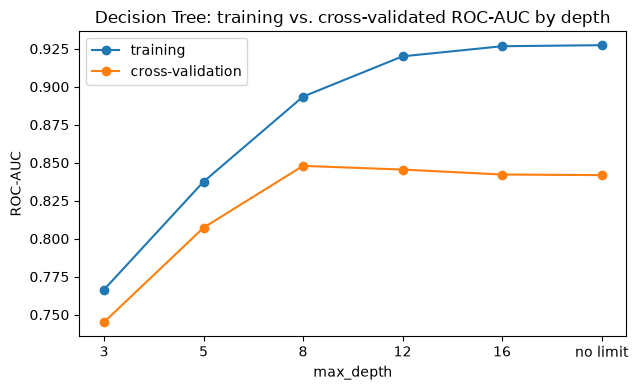

,depth,mean_train_score,mean_test_score
63,3,0.766,0.745
68,5,0.838,0.807
73,8,0.894,0.848
78,12,0.920,0.846
83,16,0.927,0.842
88,no limit,0.927,0.842


In [6]:
best = search.best_params_
same_other = cv["params"].apply(
    lambda p: all(p[k] == best[k] for k in ["min_samples_leaf", "class_weight", "criterion"])
)
depth_curve = cv.loc[same_other, ["params", "mean_train_score", "mean_test_score"]].copy()
depth_curve["depth"] = [
    "no limit" if p["max_depth"] is None else str(p["max_depth"]) for p in depth_curve["params"]
]

os.makedirs("../results", exist_ok=True)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(depth_curve["depth"], depth_curve["mean_train_score"], marker="o", label="training")
ax.plot(depth_curve["depth"], depth_curve["mean_test_score"], marker="o", label="cross-validation")
ax.set_xlabel("max_depth")
ax.set_ylabel("ROC-AUC")
ax.set_title("Decision Tree: training vs. cross-validated ROC-AUC by depth")
ax.legend()
fig.tight_layout()
fig.savefig("../results/decision_tree_depth_curve.png", dpi=200, bbox_inches="tight")
plt.show()
depth_curve[["depth", "mean_train_score", "mean_test_score"]].round(3)

## 5. Evaluate the tuned tree on the test set

In [7]:
tree = search.best_estimator_
print("depth:", tree.get_depth(), "| leaves:", tree.get_n_leaves())
pred = tree.predict(X_test)

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
base_pred = baseline.predict(X_test)
baseline_scores = {
    "train_accuracy": accuracy_score(y_train, baseline.predict(X_train)),
    "accuracy": accuracy_score(y_test, base_pred),
    "precision": 0.0, "recall": 0.0, "f1": 0.0, "roc_auc": 0.5,
}

comparison = pd.DataFrame({
    "Baseline": baseline_scores,
    "Decision Tree (untuned)": evaluate(untuned),
    "Decision Tree (tuned)": evaluate(tree),
}).T.round(3)
comparison

depth: 8 | leaves: 73


,train_accuracy,accuracy,precision,recall,f1,roc_auc
Baseline,0.589,0.565,0.000,0.000,0.000,0.500
Decision Tree (untuned),0.996,0.812,0.808,0.743,0.774,0.805
Decision Tree (tuned),0.807,0.811,0.784,0.779,0.782,0.907


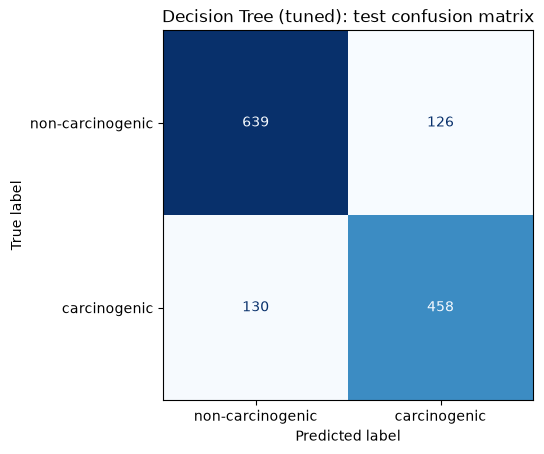

In [8]:
disp = ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                              display_labels=["non-carcinogenic", "carcinogenic"]).plot(colorbar=False, cmap="Blues")
disp.ax_.set_title("Decision Tree (tuned): test confusion matrix")
disp.figure_.savefig("../results/decision_tree_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. What the tree learned

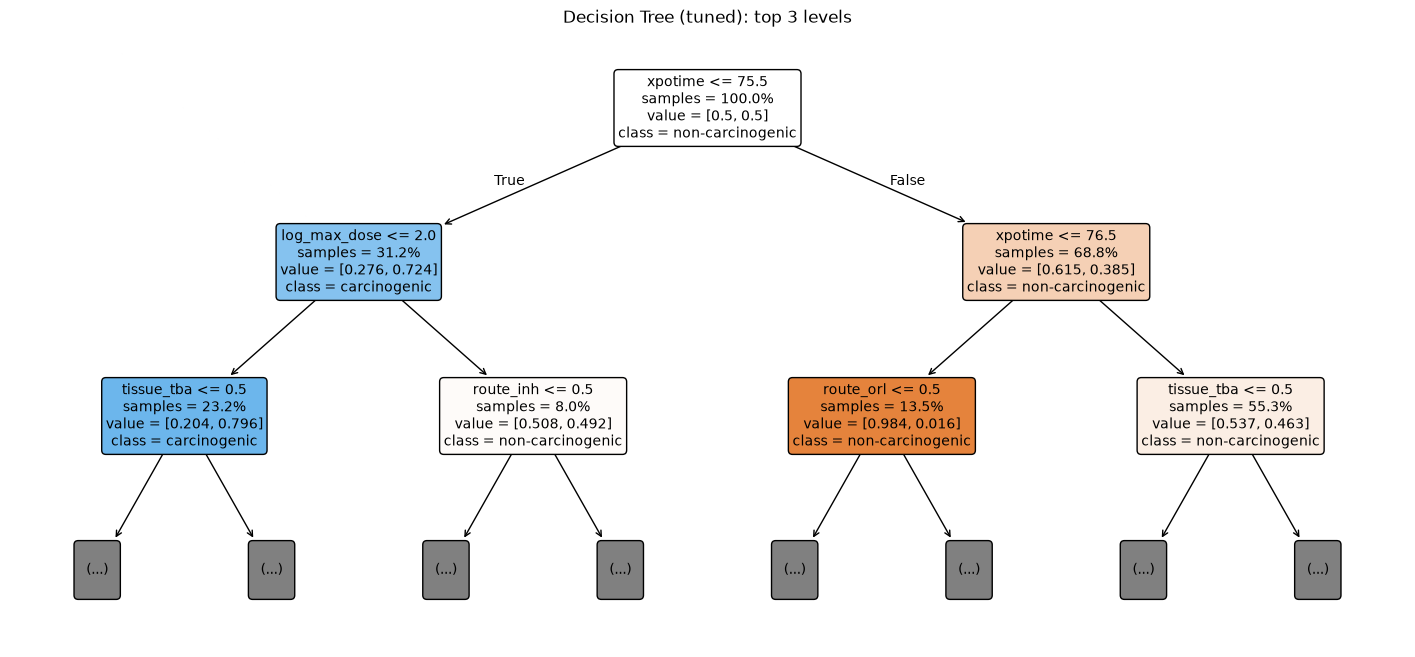

In [9]:
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(tree, max_depth=2, feature_names=X_train.columns, class_names=["non-carcinogenic", "carcinogenic"],
          filled=True, rounded=True, impurity=False, proportion=True, fontsize=10, ax=ax)
ax.set_title("Decision Tree (tuned): top 3 levels")
fig.savefig("../results/decision_tree_top_levels.png", dpi=200, bbox_inches="tight")
plt.show()

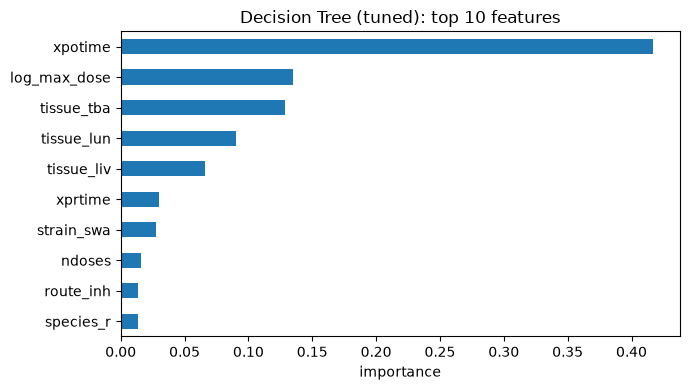

xpotime         0.417
log_max_dose    0.135
tissue_tba      0.128
tissue_lun      0.090
tissue_liv      0.066
xprtime         0.030
strain_swa      0.028
ndoses          0.016
route_inh       0.014
species_r       0.014
dtype: float64

In [10]:
importances = pd.Series(tree.feature_importances_, index=X_train.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
importances.head(10).iloc[::-1].plot(kind="barh", ax=ax)
ax.set_xlabel("importance")
ax.set_title("Decision Tree (tuned): top 10 features")
fig.tight_layout()
fig.savefig("../results/decision_tree_feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()
importances.head(10).round(3)

## 7. Decision Tree vs. Random Forest

This refits the Random Forest with the same settings as `RandomForest.ipynb` (200 trees, `max_depth=15`, `random_state=42`) on the same split, so the two can be compared side by side. The Random Forest settings were not tuned.

In [11]:
forest = RandomForestClassifier(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1).fit(X_train, y_train)
comparison.loc["Random Forest"] = pd.Series(evaluate(forest)).round(3)
comparison

,train_accuracy,accuracy,precision,recall,f1,roc_auc
Baseline,0.589,0.565,0.000,0.000,0.000,0.500
Decision Tree (untuned),0.996,0.812,0.808,0.743,0.774,0.805
Decision Tree (tuned),0.807,0.811,0.784,0.779,0.782,0.907
Random Forest,0.906,0.841,0.880,0.735,0.801,0.937


In [12]:
comparison.drop(columns="train_accuracy").to_csv("../results/decision_tree_results.csv")

## Conclusion

- **The untuned tree overfits.** With no limits it grows 42 levels deep with 849 leaves, scores 99.6% accuracy on the training rows, and drops to a test ROC-AUC of 0.805.
- **Tuning fixes most of that.** Cross-validation grouped by chemical picked `max_depth=8`, `min_samples_leaf=20`, and `class_weight="balanced"`. The tuned tree has 73 leaves, its training and test accuracy are about the same (0.807 vs. 0.811), and test ROC-AUC rises to 0.907. The depth curve shows the cross-validated score peaking at depth 8 while the training score keeps climbing.
- **Recall is the tree's strength.** The tuned tree catches 77.9% of carcinogenic records (recall 0.779), higher than the Random Forest (0.735), with an F1 of 0.782. Balanced class weights push it toward flagging positives, at the cost of lower precision (0.784 vs. 0.880).
- **The Random Forest ranks better overall.** It has the higher ROC-AUC (0.937 vs. 0.907) and accuracy (0.841 vs. 0.811). Averaging many trees smooths out the single tree's hard cutoffs. The forest was not tuned, so its lead could grow if it were.
- **What drives the predictions.** Exposure time (`xpotime`) is by far the most important feature (0.417), followed by the log of the maximum dose (0.135) and the organ examined: all tumor-bearing animals (`tissue_tba`), lung, and liver. Organ is a major signal, which matches the KNN finding that removing tissue lowers performance.
- **Limitations.** These are predictions of the author's opinion for one experiment and organ, not a direct measure of a chemical's danger. Exposure time and dose describe how the experiment was designed, so part of the signal may reflect study design rather than chemistry.